# Q1D | Train Linear Regression

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset, so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- 20 shared folds: four-fold cross validation cut 5 times, scored by RMSE in `Life Ladder` points. A change is real only when its Δrmse clears 1 SE.

**Feature set**
- Shapes pay off: Q1B's bends for `Social support` and `Healthy life expectancy at birth`, a hinge on `Generosity` and `Negative affect` dropped take the closed form to 0.5175 from 0.5470 on the raw attributes (SE 0.0069), so every later model uses them.
- Missing values do not matter: no imputer, with or without missing flags, beats the median by 1 SE, and dropping the incomplete rows still ties after the shapes.

**Closed form vs SGD**
- SGD gets there with a new schedule: plain SGD stops after at most 7 epochs, slightly worse (+0.0003); with `adaptive` and `eta0` 0.001 it ties the closed form at 0.5175.

**Other hyperparameters**
- The schedule decides convergence: across all 24 schedule and `eta0` pairs, `adaptive` is the only schedule that wins (-0.0003, SE 0.0003, a candidate at 0.001, 0.01 and 1). 0.001 is carried, at the cost of more epochs (33 against 7).
- The other schedules need the step just right or fail: `constant` and `invscaling` at best tie (`constant` at 0.001: -0.0004, SE 0.0007), `optimal` diverges at every step, and 0.00001 stops too early under every schedule.

**Regularization**
- Small penalties change nothing: up to alpha 0.01, every penalty stays within 0.0005 of no penalty.
- L1 bites first: at alpha 0.1, Lasso is worse by 0.0275 and Elastic Net costs more as its share of L1 grows, while Ridge is still within noise.
- Large penalties underfit, then predict the mean: Ridge at alpha 10 raises training and validation RMSE together (0.9055 and 0.9164), and Lasso at alpha 1 reaches Dummy's RMSE (1.1280 against 1.1281).
- Nothing to cure: without a penalty, training RMSE (0.5186) already sits above validation RMSE (0.5175).

**Selected model**
- Ridge at alpha 0.01, picked as required: the lowest mean (0.5174), 0.0001 below no penalty, within noise of it.
- Trained on all 1,559 rows and saved: 32 epochs, training RMSE 0.5181.

**Loss by epoch**
- Learns fast, then holds: both lines start within 0.01 of where they finish and are flat from about epoch 11. Validation stays below training at every epoch, so more epochs do not overfit.
- Drawn by refitting with `max_iter=k`; the hint's loop restarts the schedule.

**Reproducibility**
- Seed 42 for the fold cuts, the iterative imputer and every SGD model.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.experimental import enable_iterative_imputer  # makes IterativeImputer importable
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import Q1.consts as Q1_CONSTS
from consts import SEED, CV_SPLITS, MAX_ITER, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIOS

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)  # a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=Q1_CONSTS.TRAIN_PATH)

ATTRIBUTES = [column for column in train_df.columns if column != Q1_CONSTS.TARGET]
X, y = train_df[ATTRIBUTES], train_df[Q1_CONSTS.TARGET]

# Setup

## Folds

In [3]:
# Validation rows are complete rows only, as in the test file. The incomplete rows are added to the training side of
# every fold, so a model that imputes them and one that drops them are scored on the same validation rows.
complete = np.flatnonzero(X.notna().all(axis=1))
incomplete = np.flatnonzero(X.isna().any(axis=1))
cuts = RepeatedKFold(n_splits=CV_SPLITS, n_repeats=Q1_CONSTS.CV_REPEATS, random_state=SEED).split(complete)
FOLDS = [(np.concatenate([complete[train], incomplete]), complete[validation]) for train, validation in cuts]
DROP_FOLDS = [(train[np.isin(train, complete)], validation) for train, validation in FOLDS]  # the same folds without the incomplete rows

pd.DataFrame({
	'folds': [len(FOLDS), len(DROP_FOLDS)],
	'training rows': [f'{min(len(t) for t, _ in folds)} to {max(len(t) for t, _ in folds)}' for folds in (FOLDS, DROP_FOLDS)],
	'validation rows': [f'{min(len(v) for _, v in folds)} to {max(len(v) for _, v in folds)}' for folds in (FOLDS, DROP_FOLDS)],
}, index=['FOLDS (incomplete rows imputed)', 'DROP_FOLDS (incomplete rows dropped)'])

,folds,training rows,validation rows
FOLDS (incomplete rows imputed),20,1215 to 1216,343 to 344
DROP_FOLDS (incomplete rows dropped),20,1030 to 1031,343 to 344


## Runs

In [4]:
MEDIAN = SimpleImputer(strategy='median')  # Q1B's preprocessing note: fill a missing value with its attribute's median
RUNS = {}  # every cross validation result, keyed by name

def build(model, shapes=None, imputer=MEDIAN):
	"""The pipeline of one experiment: imputer, shapes, standardized columns, model (see PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=shapes, imputer=imputer)

def score(name, pipeline, folds=FOLDS):
	"""Cross validate a pipeline and keep its result under name."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=folds)

def table(names, baseline):
	"""The baseline's result, then each of names with its change against the baseline."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in [baseline, *names]}, baseline=baseline, folds=FOLDS)

def compare(baseline, candidate):
	"""The RMSE of both on every fold, beside the candidate's change on every fold."""
	PLOTTING.fold_comparison(runs=RUNS, baseline=baseline, candidate=candidate, folds=FOLDS, repeat_size=CV_SPLITS)

def deltas(names, baseline):
	"""Each of names' change against the baseline on every fold, one row each."""
	PLOTTING.fold_deltas(runs=RUNS, baseline=baseline, names=names, folds=FOLDS)

# Method

- **Metric:** RMSE in `Life Ladder` points, on the validation rows of each fold. The training RMSE next to it shows how much better a model fits the rows it was trained on.
- **Folds:** four-fold cross validation, cut 5 times from a new shuffle each time (`RepeatedKFold`, seed 42), so 20 folds. Every model is scored on the same 20 folds, so two models are compared fold by fold. Validation rows are the 1,374 complete rows only, as the test file has no missing values. The 185 incomplete rows always sit on the training side.
- **Noise:** Δrmse is the mean change in validation RMSE against the baseline, and SE its standard error, widened because the folds share most of their training rows (Nadeau and Bengio). Verdict: **candidate** when Δrmse is below -1 SE, **worse** when above +1 SE, **within noise** in between.
- **Carry rules:** a change is carried only when it is a candidate. Within noise, the simpler model stays: a feature change back to the raw attribute is taken, any other change is not, and a hyperparameter keeps its current value. Combined puts the carried feature changes together and is kept when its mean is below the strongest combination's.
- **Selected model:** the homework asks for one regularized model, so the regularized setting with the lowest mean validation RMSE is selected, even when it only ties the others.
- **Drop One:** an attribute stays in the model only when dropping it raises the mean validation RMSE (see Drop One).
- **Pipeline:** every model is one pipeline that takes the 8 raw attributes: imputer, shapes, standardized columns, model. The target is standardized too and the predictions turned back into `Life Ladder` points. Each step is fit on the training rows of a fold only.
- **Shapes:** taken from Q1B's screen (`STATISTICS.shape_fits`) with the settings it found. Those settings were searched on all train rows, validation rows included, so shape results are a little optimistic.
- **Optimism:** every choice is made on these folds, so their scores are a little optimistic. The test set gives the honest estimate.

# Baselines

## Dummy and Closed Form

In [5]:
score('Dummy', build(DummyRegressor()))  # predicts the training mean of every fold
score('Closed form', build(LinearRegression()))  # least squares, solved by SVD

table(['Closed form'], baseline='Dummy')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Dummy,1.1281,1.1085,NaN,NaN,,baseline
Closed form,0.5470,0.5455,-0.5811,0.0237,20 of 20,candidate


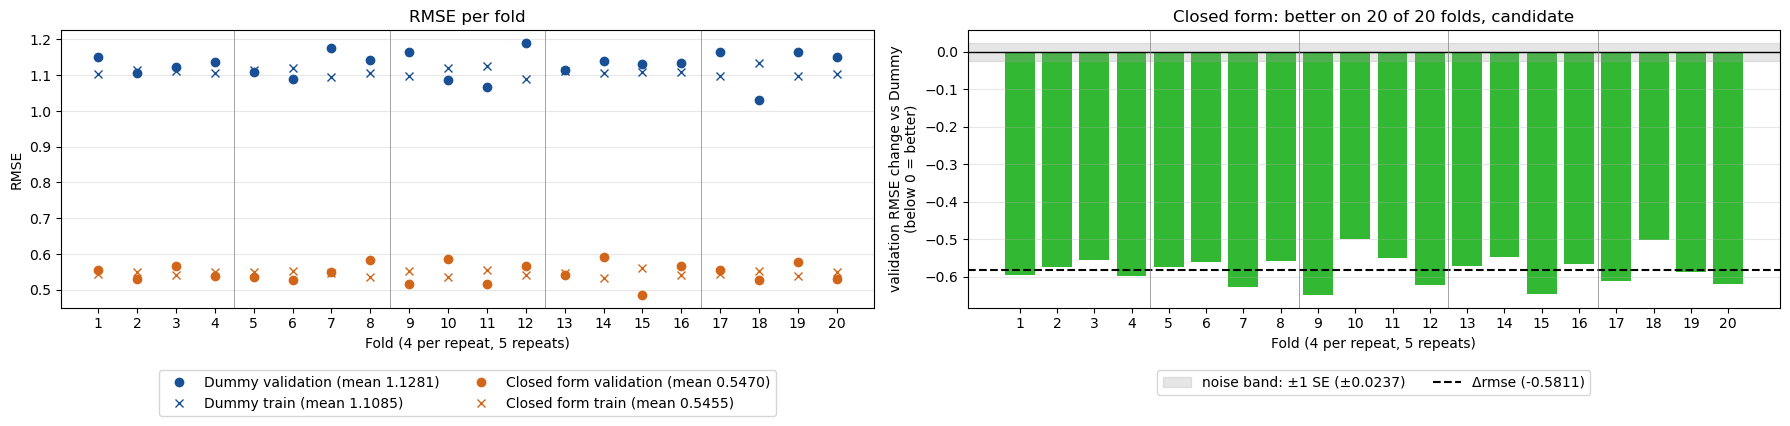

In [6]:
compare('Dummy', 'Closed form')

### Notes / Observations

- Closed form far ahead of the mean: validation RMSE 0.5470 against 1.1281 for Dummy, better on all 20 folds. The 8 raw attributes already cut the error by more than half, so this is the bar every later tier has to beat.
- No overfitting to cure: training RMSE is 0.5455 against 0.5470 on validation rows, so the straight line on 8 columns is not fitting noise. Any gain from here has to come from shapes or attributes, and a penalty has little gap to close.

# Missing Values

The baseline fills a missing value with its attribute's median. Each row below handles the 185 incomplete training rows another way, on the same validation rows:
- **Drop incomplete rows:** train on the complete rows only.
- **Mean:** fill with the attribute's mean.
- **KNN:** fill with the mean of the 5 most similar rows, measured on standardized attributes.
- **Iterative:** predict each missing value from the other attributes, in rounds.
- **+ missing flags:** each imputer again, plus a 0/1 column per attribute marking the filled rows. Q1B flagged one as worth testing on `Perceptions of corruption` and `Generosity`, the two attributes with the most missing values.

In [7]:
score('Drop incomplete rows', build(LinearRegression(), imputer=None), folds=DROP_FOLDS)
score('Mean', build(LinearRegression(), imputer=SimpleImputer(strategy='mean')))
score('Mean + missing flags', build(LinearRegression(), imputer=SimpleImputer(strategy='mean', add_indicator=True)))
score('Median + missing flags', build(LinearRegression(), imputer=SimpleImputer(strategy='median', add_indicator=True)))
# KNN's output stays standardized, so it is only used without shapes
score('KNN', build(LinearRegression(), imputer=make_pipeline(StandardScaler(), KNNImputer())))
score('KNN + missing flags', build(LinearRegression(), imputer=make_pipeline(StandardScaler(), KNNImputer(add_indicator=True))))
score('Iterative', build(LinearRegression(), imputer=IterativeImputer(random_state=SEED)))
score('Iterative + missing flags', build(LinearRegression(), imputer=IterativeImputer(random_state=SEED, add_indicator=True)))

MISSING = [
	'Drop incomplete rows',
	'Mean', 'Mean + missing flags',
	'Median + missing flags',
	'KNN', 'KNN + missing flags',
	'Iterative', 'Iterative + missing flags',
]
table(MISSING, baseline='Closed form')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Closed form,0.5470,0.5455,NaN,NaN,,baseline
Drop incomplete rows,0.5466,0.5412,-0.0003,0.0018,12 of 20,within noise
Mean,0.5470,0.5450,0.0001,0.0001,6 of 20,within noise
Mean + missing flags,0.5468,0.5364,-0.0002,0.0004,11 of 20,within noise
Median + missing flags,0.5468,0.5364,-0.0002,0.0004,11 of 20,within noise
KNN,0.5468,0.5452,-0.0002,0.0009,10 of 20,within noise
KNN + missing flags,0.5465,0.5364,-0.0004,0.0008,12 of 20,within noise
Iterative,0.5471,0.5473,0.0001,0.0011,8 of 20,within noise
Iterative + missing flags,0.5468,0.5393,-0.0002,0.0010,8 of 20,within noise


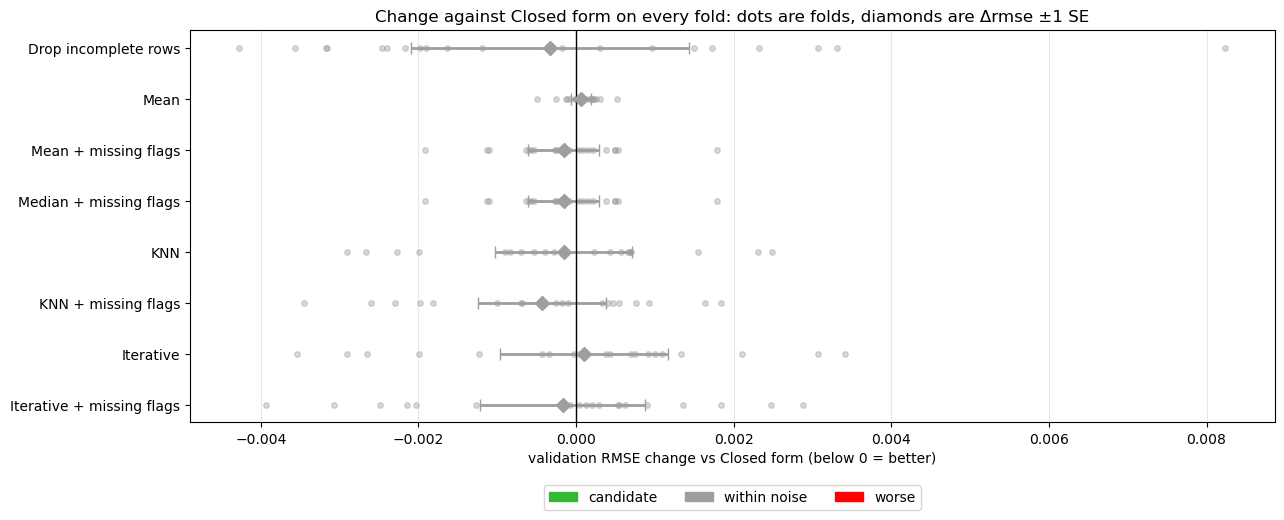

In [8]:
deltas(MISSING, baseline='Closed form')

### Notes / Observations

- Every alternative ties with the median: all 8 Δrmse values lie between -0.0004 and +0.0001, each within 1 SE. How the 185 incomplete rows are filled, or whether they are dropped, does not change the validation RMSE, so the median stays as the carried imputer.
- Missing flags only help on training rows: with every imputer they lower training RMSE (0.5364 to 0.5393, against 0.5450 to 0.5473 without), while validation RMSE moves by at most 0.0003. What the flags learn does not carry over to new rows.
- With flags, mean and median give the same model: Mean + missing flags matches Median + missing flags on every number. Both fill an attribute with one value, and the flag's coefficient shifts to absorb whichever value it is.
- Recheck after shapes: a shape bends an attribute at a threshold, so a filled-in value near that threshold can matter more than on the raw scale. Drop against median is retested on the carried feature set.

# Feature Shapes

The strongest combination takes Q1B's recommended shape for each attribute that has one. Each experiment then changes one thing against it, from Q1B's other shapes and Q1C's overlaps:

| Attribute | In the strongest combination | Tested against it |
|---|---|---|
| `Social support` | reciprocal, 1 / (1.2 - x) | hinge at 0.844, raw |
| `Healthy life expectancy at birth` | floor at 56.8 | hinge at 57.5, raw, dropped (r 0.851 with `Log GDP per capita` in Q1C) |
| `Freedom to make life choices` | hinge at 0.8 | reciprocal, 1 / (1.2 - x), raw |
| `Generosity` | high generosity flag, x ≥ 0.087 | hinge at 0.305, raw, dropped |
| `Log GDP per capita` | raw | hinge at 10.1 |
| `Negative affect` | raw | hinge at 0.202, dropped |
| `Perceptions of corruption`, `Positive affect` | raw | nothing: Q1B found no shape worth testing |

Every model in this section is the closed form, with the median imputer.

In [9]:
GDP, SOCIAL, LIFE_EXP, FREEDOM, GENEROSITY, CORRUPTION, POS_AFFECT, NEG_AFFECT = ATTRIBUTES
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q1_CONSTS.TARGET) for attribute in ATTRIBUTES}

def shape(attribute, name):
	"""Q1B's shape of an attribute by name (ex 'hinge'), with the setting Q1B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

## Strongest Combination

In [10]:
SHAPES = {
	GDP: 'passthrough',
	SOCIAL: shape(SOCIAL, 'reciprocal'),
	LIFE_EXP: shape(LIFE_EXP, 'floor'),
	FREEDOM: shape(FREEDOM, 'hinge'),
	GENEROSITY: shape(GENEROSITY, 'step'),
	CORRUPTION: 'passthrough',
	POS_AFFECT: 'passthrough',
	NEG_AFFECT: 'passthrough',
}
score('Shapes', build(LinearRegression(), SHAPES))

table(['Shapes'], baseline='Closed form')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Closed form,0.5470,0.5455,NaN,NaN,,baseline
Shapes,0.5225,0.5230,-0.0245,0.0054,19 of 20,candidate


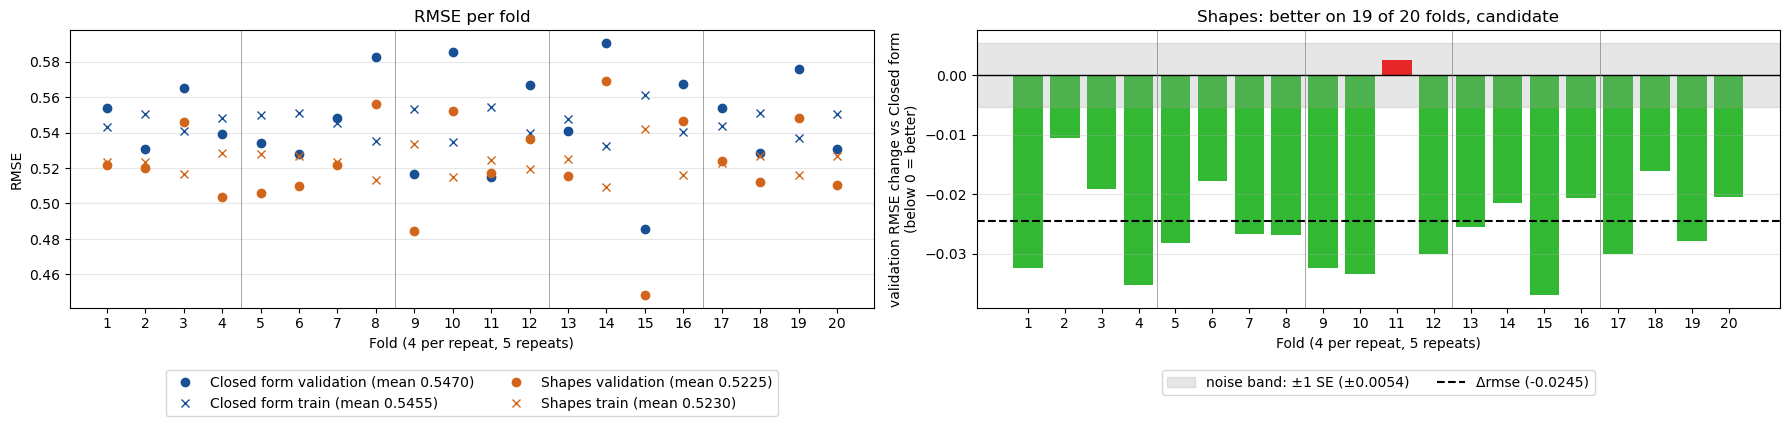

In [11]:
compare('Closed form', 'Shapes')

### Notes / Observations

- Q1B's bends hold in the full model: the shapes cut validation RMSE to 0.5225 from 0.5470, better on 19 of 20 folds. A gain measured one attribute at a time survives next to the other 7 attributes.
- The gain is on new rows too: training RMSE falls by about as much (0.5455 to 0.5230), so the shapes fit the trend better rather than fitting noise in the training rows.

## Experiments

Each row changes one thing against `Shapes`: an attribute back to raw, another of its shapes in place of the one used, a shape added to a raw attribute, or the attribute dropped.

In [12]:
EXPERIMENTS = {
	'Raw: Social': {**SHAPES, SOCIAL: 'passthrough'},
	'Raw: Life exp': {**SHAPES, LIFE_EXP: 'passthrough'},
	'Raw: Freedom': {**SHAPES, FREEDOM: 'passthrough'},
	'Raw: Generosity': {**SHAPES, GENEROSITY: 'passthrough'},
	'Swap: Social hinge': {**SHAPES, SOCIAL: shape(SOCIAL, 'hinge')},
	'Swap: Life exp hinge': {**SHAPES, LIFE_EXP: shape(LIFE_EXP, 'hinge')},
	'Swap: Freedom reciprocal': {**SHAPES, FREEDOM: shape(FREEDOM, 'reciprocal')},
	'Swap: Generosity hinge': {**SHAPES, GENEROSITY: shape(GENEROSITY, 'hinge')},
	'Add: GDP hinge': {**SHAPES, GDP: shape(GDP, 'hinge')},
	'Add: Neg affect hinge': {**SHAPES, NEG_AFFECT: shape(NEG_AFFECT, 'hinge')},
	'Drop: Generosity': {**SHAPES, GENEROSITY: 'drop'},
	'Drop: Neg affect': {**SHAPES, NEG_AFFECT: 'drop'},
	'Drop: Life exp': {**SHAPES, LIFE_EXP: 'drop'},
}
for name, shapes in EXPERIMENTS.items():
	score(name, build(LinearRegression(), shapes))

table(list(EXPERIMENTS), baseline='Shapes')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Shapes,0.5225,0.5230,NaN,NaN,,baseline
Raw: Social,0.5308,0.5313,0.0084,0.0027,1 of 20,worse
Raw: Life exp,0.5371,0.5347,0.0146,0.0037,1 of 20,worse
Raw: Freedom,0.5221,0.5233,-0.0003,0.0005,11 of 20,within noise
Raw: Generosity,0.5220,0.5221,-0.0005,0.0010,15 of 20,within noise
Swap: Social hinge,0.5225,0.5223,0.0000,0.0015,11 of 20,within noise
Swap: Life exp hinge,0.5224,0.5225,-0.0001,0.0012,15 of 20,within noise
Swap: Freedom reciprocal,0.5223,0.5231,-0.0002,0.0003,13 of 20,within noise
Swap: Generosity hinge,0.5184,0.5184,-0.0041,0.0020,17 of 20,candidate
Add: GDP hinge,0.5224,0.5200,-0.0000,0.0022,11 of 20,within noise


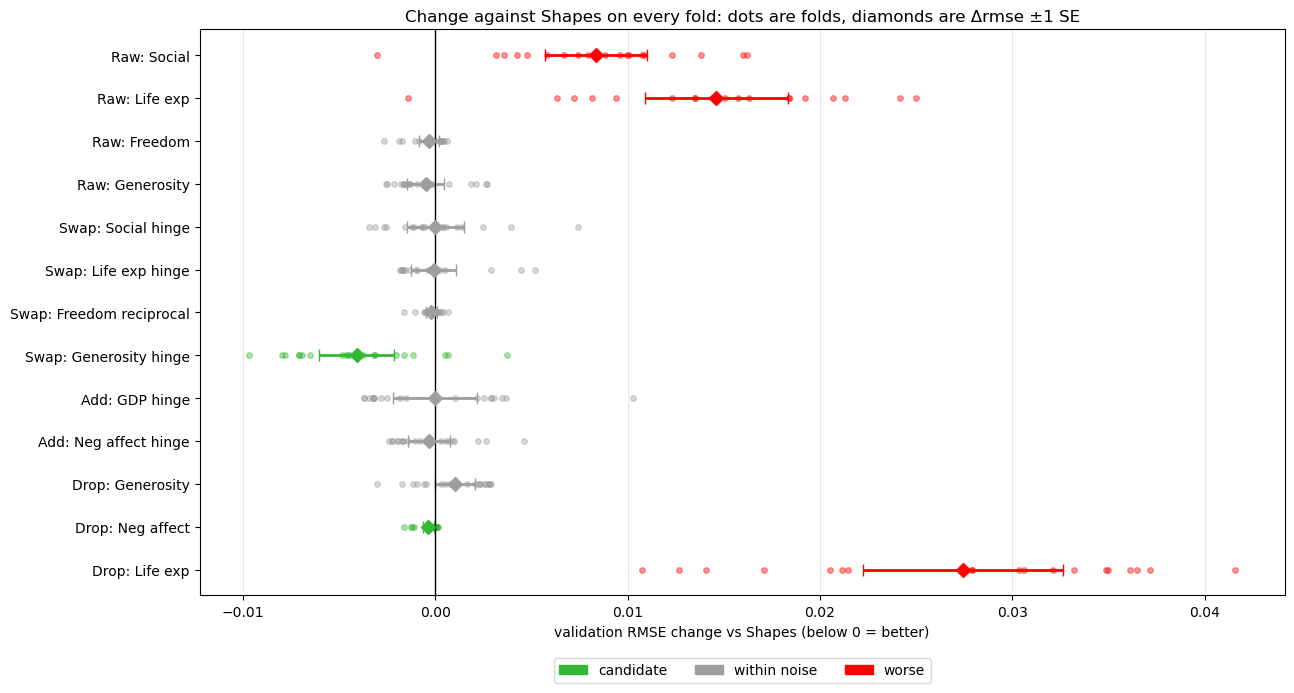

In [13]:
deltas(list(EXPERIMENTS), baseline='Shapes')

### Notes / Observations

- Two shapes carry the gain: putting `Social support` or `Healthy life expectancy at birth` back to raw is worse (+0.0084 and +0.0146). Their bends are what the model needs most.
- `Generosity` works better as a slope than as a flag: its hinge at 0.305 beats the flag at 0.087 by 0.0041 (SE 0.0020), on 17 of 20 folds.
- `Freedom to make life choices` gets nothing from its shape: back to raw and the reciprocal both tie with the hinge, so the simpler raw column is carried.
- Ties keep the one-column shapes: the hinges for `Social support` and `Healthy life expectancy at birth`, and the hinges added on `Log GDP per capita` and `Negative affect`, are all within noise. A second column adds nothing.
- `Healthy life expectancy at birth` is no copy of `Log GDP per capita`: dropping it is worse on all 20 folds (+0.0274), so both stay despite their overlap.

## Combined

Every candidate, plus every change back to raw that is within noise (it makes the model simpler), together. A drop that is only within noise is left to Drop One, which removes one attribute at a time, so two attributes that cover for each other cannot leave together. When several rows touch the same attribute, the one with the lowest rmse wins. If Combined has a higher mean than `Shapes`, the best single change is carried instead.

In [14]:
COMBINED = {
	GDP: 'passthrough',
	SOCIAL: shape(SOCIAL, 'reciprocal'),
	LIFE_EXP: shape(LIFE_EXP, 'floor'),
	FREEDOM: 'passthrough',  # back to raw: within noise, and simpler than its hinge
	GENEROSITY: shape(GENEROSITY, 'hinge'),  # candidate, and the lowest rmse of the 4 Generosity rows
	CORRUPTION: 'passthrough',
	POS_AFFECT: 'passthrough',
	NEG_AFFECT: 'drop',  # candidate
}
score('Combined', build(LinearRegression(), COMBINED))

table(['Combined'], baseline='Shapes')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Shapes,0.5225,0.5230,NaN,NaN,,baseline
Combined,0.5175,0.5186,-0.0049,0.0022,18 of 20,candidate


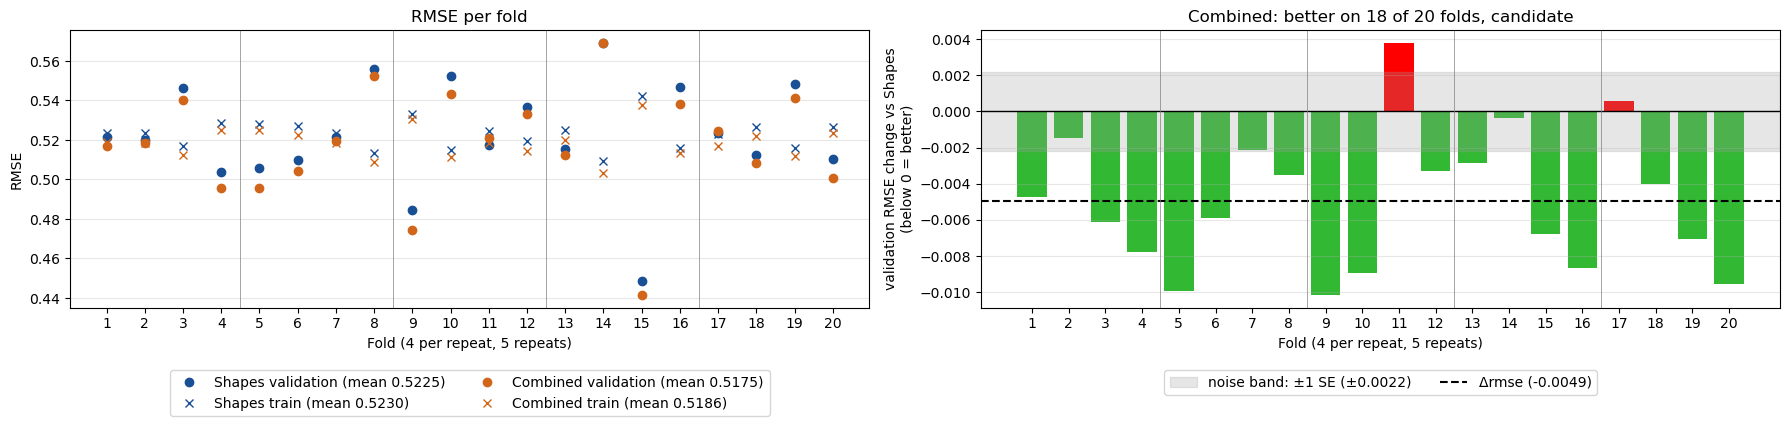

In [15]:
compare('Shapes', 'Combined')

### Notes / Observations

- The three changes add up: Combined beats `Shapes` by 0.0049 (SE 0.0022), on 18 of 20 folds, more than `Generosity`'s hinge alone (0.0041).
- Fewer columns, no loss: dropping `Negative affect` and putting `Freedom to make life choices` back to raw cost nothing, so the model gets simpler and better at once.

# Drop One

Every attribute left in the model has to earn its place: dropping it must raise the mean validation RMSE. Each round drops every remaining attribute one at a time. When some drops do not raise the mean, the cheapest of them (the lowest rmse once dropped) first gets its other Q1B shapes, and one that beats the drop on the mean earns the attribute its place. Otherwise the attribute is dropped and the next round starts from the smaller model, so two attributes that cover for each other cannot leave together. The rounds end when every drop raises the mean.

The mean is used here, not the 1 SE rule: the 1 SE rule asks whether a change is real, while Drop One only asks whether the model is better with the attribute or without it. With few folds, the SE can be too wide to confirm a cost the model really pays, and the rounds would strip attributes it needs.

In [16]:
def drop_one(shapes, prefix, model=LinearRegression()):
	"""Score the model (closed form unless given) of shapes with each attribute still in it dropped, one at a time, and return the run names."""
	names = []
	for attribute in ATTRIBUTES:
		if shapes.get(attribute) != 'drop':
			name = f'{prefix}: drop {Q1_CONSTS.SHORT_NAMES[attribute]}'
			score(name, build(model, {**shapes, attribute: 'drop'}))
			names.append(name)
	return names

## Round 1

In [17]:
ROUND_1 = drop_one(COMBINED, 'Round 1')

table(ROUND_1, baseline='Combined')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Combined,0.5175,0.5186,NaN,NaN,,baseline
Round 1: drop GDP,0.5332,0.5416,0.0157,0.0040,0 of 20,worse
Round 1: drop Social,0.5395,0.5441,0.0220,0.0061,1 of 20,worse
Round 1: drop Life exp,0.5440,0.5446,0.0265,0.0052,0 of 20,worse
Round 1: drop Freedom,0.5181,0.5203,0.0006,0.0011,7 of 20,within noise
Round 1: drop Generosity,0.5231,0.5247,0.0056,0.0028,3 of 20,worse
Round 1: drop Corruption,0.5200,0.5204,0.0025,0.0017,3 of 20,worse
Round 1: drop Pos affect,0.5415,0.5457,0.0240,0.0046,0 of 20,worse


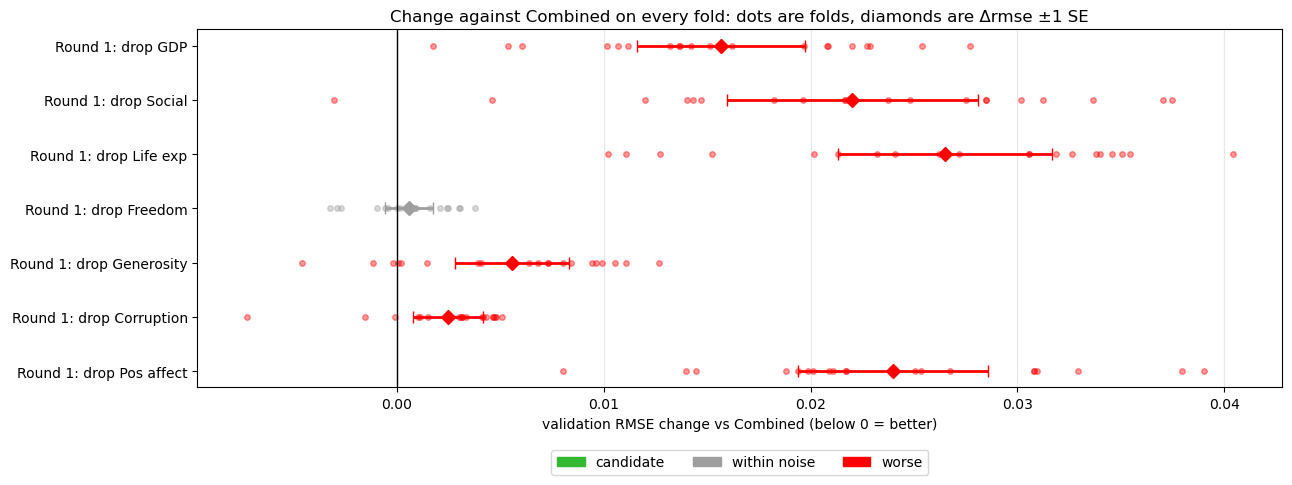

In [18]:
deltas(ROUND_1, baseline='Combined')

### Notes / Observations

- Every attribute earns its place, so the rounds end after one: each drop raises the mean validation RMSE.
- `Freedom to make life choices` is the closest call: dropping it costs +0.0006 (SE 0.0011) and is better on 7 of 20 folds. It is too small to clear 1 SE, but the model is better with it on average, so it stays.
- The biggest costs are `Healthy life expectancy at birth` (+0.0265) and `Positive affect` (+0.0240), more than `Log GDP per capita` (+0.0157).

## Feature Set

In [19]:
FEATURES = COMBINED  # every drop in round 1 raises the mean validation RMSE, so the rounds end here
score('Closed form, features', build(LinearRegression(), FEATURES))

# Missing Recheck

Median against dropping the incomplete rows, on the carried feature set.

In [20]:
score('Features, drop incomplete rows', build(LinearRegression(), FEATURES, imputer=None), folds=DROP_FOLDS)

table(['Features, drop incomplete rows'], baseline='Closed form, features')

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Closed form, features",0.5175,0.5186,NaN,NaN,,baseline
"Features, drop incomplete rows",0.5176,0.5131,0.0001,0.0013,12 of 20,within noise


### Notes / Observations

- The shapes do not make the incomplete rows matter: dropping them changes validation RMSE by +0.0001 (SE 0.0013), so the median stays. As with the raw attributes, dropping only lowers training RMSE (0.5131).

# Carried Feature Set

The feature set every model from here on uses, against the closed form on the 8 raw attributes.

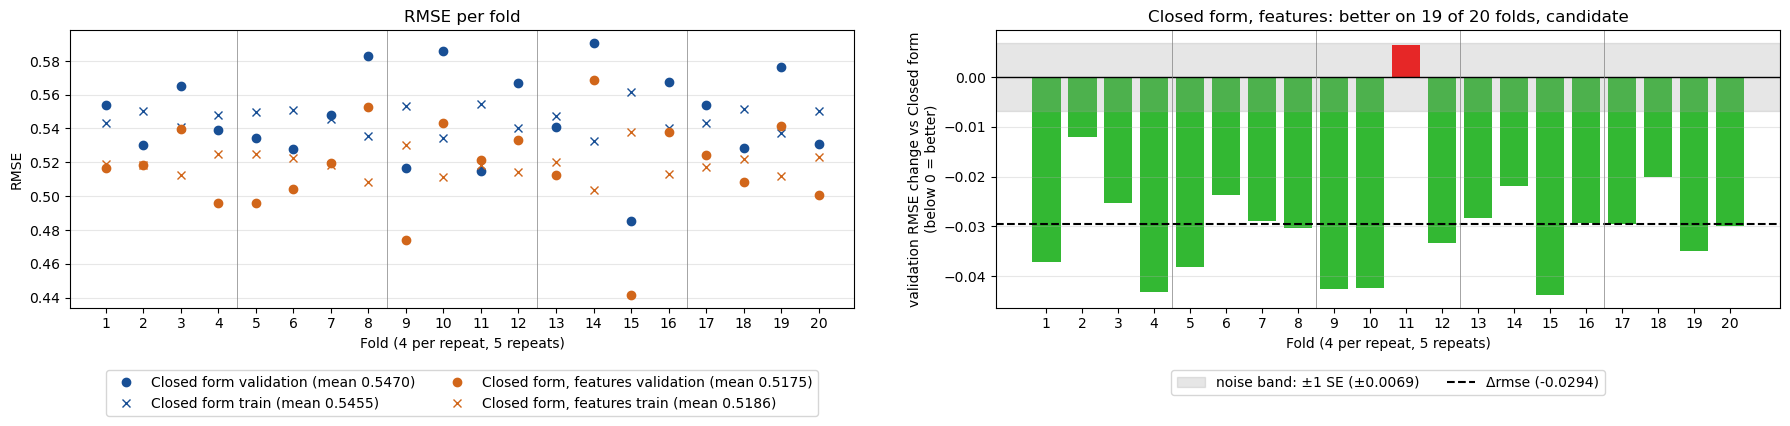

In [21]:
compare('Closed form', 'Closed form, features')

### Notes / Observations

- The carried feature set: 7 attributes in 8 columns, better than the 8 raw attributes by 0.0294 (SE 0.0069), on 19 of 20 folds. Fold 11 is the only one where the raw model wins.
- Training RMSE (0.5186) sits just above validation RMSE (0.5175): the training rows include the 185 imputed rows, the validation rows do not. There is no sign of overfitting for a penalty to fix.

# SGD

`SGDRegressor` on the carried feature set. Every setting is written out, none left to a default: `penalty=None` (the default is a light L2 penalty), the learning rate schedule, `eta0`, `power_t`, `max_iter` and `tol`. `max_iter` is only a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row.

In [22]:
YMAX = 1.2  # a little above Dummy's RMSE: a run that diverges is drawn at the top of the chart instead of flattening the rest
SGD_SETTINGS = dict(
	penalty=None,
	learning_rate='invscaling',  # step = eta0 / t ** power_t, shrinking as training goes on
	eta0=0.01,
	power_t=0.25,
	average=False,
	max_iter=MAX_ITER,
	tol=1e-3,
	random_state=SEED,
)
SETTINGS = {}  # the settings of every SGD run, keyed by name

def sgd(name, settings):
	"""Cross validate SGD with these settings on the carried feature set, and keep the settings under name."""
	SETTINGS[name] = settings
	score(name, build(SGDRegressor(**settings), FEATURES))

def sweep(parameter, values, settings, baseline, prefix='', log_x=False):
	"""Cross validate SGD at each value of one parameter, the others at settings, and show the table and the chart
	against baseline. Return the run names, keyed by value."""
	names = {value: f'{prefix}{parameter}={value}' for value in values}
	for value, name in names.items():
		sgd(name, {**settings, parameter: value})
	display(table(list(names.values()), baseline=baseline))
	PLOTTING.parameter_search(
		runs={value: RUNS[name] for value, name in names.items()},
		parameter=parameter,
		log_x=log_x,
		reference=(baseline, RUNS[baseline]),
		ymax=YMAX,
		title=f'{prefix}{parameter}: RMSE on every fold',
	)
	return names

def cross(first, first_values, second, second_values, settings, baseline=None, prefix='', log_x=False):
	"""Cross validate SGD at every pair of values of two parameters, the others at settings, and show the table and the
	chart against baseline (the run at the current pair when omitted). Return the run names, keyed by pair. log_x
	applies to second."""
	names = {(a, b): f'{prefix}{first}={a}, {second}={b}' for a in first_values for b in second_values}
	for (a, b), name in names.items():
		sgd(name, {**settings, first: a, second: b})
	if baseline is None:
		baseline = names[(settings[first], settings[second])]
	display(table([name for name in names.values() if name != baseline], baseline=baseline))
	PLOTTING.parameter_cross(
		runs={pair: RUNS[name] for pair, name in names.items()},
		lines=first,
		x=second,
		log_x=log_x,
		reference=None if baseline in names.values() else (baseline, RUNS[baseline]),
		ymax=YMAX,
	)
	return names

def carried(names, current):
	"""The carry rule: of the runs in names (keyed by value) that are candidates against the run at current, the value
	with the lowest mean, or current when none is."""
	candidates = [
		value for value, name in names.items()
		if STATISTICS.fold_difference(baseline=RUNS[names[current]], candidate=RUNS[name], folds=FOLDS).verdict == 'candidate'
	]
	return min(candidates, key=lambda value: RUNS[names[value]]['validation rmse'].mean(), default=current)

## SGD vs Closed Form

In [23]:
sgd('SGD', SGD_SETTINGS)

table(['SGD'], baseline='Closed form, features')

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Closed form, features",0.5175,0.5186,NaN,NaN,,baseline,<NA>
SGD,0.5178,0.5188,0.0003,0.0003,4 of 20,worse,7


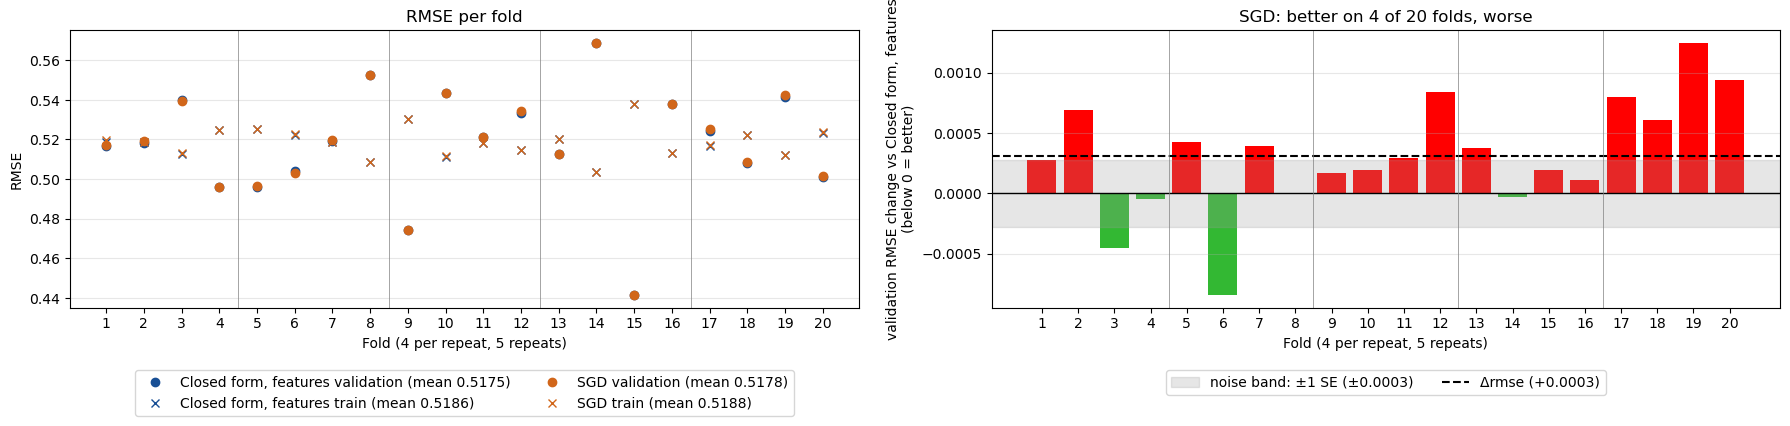

In [24]:
compare('Closed form, features', 'SGD')

### Notes / Observations

- Plain SGD stops just short of the closed form: +0.0003 (SE 0.0003), better on only 4 of 20 folds, and worse by less than 0.0013 on every fold. With the default `invscaling` step it stops after at most 7 epochs, before reaching the exact least squares coefficients.

## Hyperparameter Searches

The learning rate schedule and its starting step `eta0` are searched together, every pair of the 4 schedules and 6 steps, since a schedule only sets how the step changes from `eta0`. The table compares each pair against the current settings (its baseline row), and a pair replaces them only when it is a candidate. Of several candidates, the lowest mean wins.

### Learning Rate Schedule × eta0 (Starting Step Size)

`optimal` sets its own step from `alpha` and ignores `eta0`, so its 6 rows are the same model.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"learning_rate=invscaling, eta0=0.01",0.5178,0.5188,NaN,NaN,,baseline,7
"learning_rate=constant, eta0=1e-05",0.5443,0.5489,0.0265,0.0054,0 of 20,worse,50
"learning_rate=constant, eta0=0.0001",0.5194,0.5223,0.0015,0.0022,6 of 20,within noise,14
"learning_rate=constant, eta0=0.001",0.5174,0.5189,-0.0004,0.0007,11 of 20,within noise,8
"learning_rate=constant, eta0=0.01",0.5307,0.5296,0.0128,0.0041,0 of 20,worse,11
"learning_rate=constant, eta0=0.1",185571496658.8870,199784815957.7226,185571496658.3692,138732982984.9310,0 of 20,worse,7
"learning_rate=constant, eta0=1",7340727618732.8164,7221437575849.5244,7340727618732.2988,1867780175871.3303,0 of 20,worse,18
"learning_rate=optimal, eta0=1e-05",363034303202.0000,344079166364.3774,363034303201.4821,192834798101.1468,0 of 20,worse,75
"learning_rate=optimal, eta0=0.0001",363034303202.0000,344079166364.3774,363034303201.4821,192834798101.1468,0 of 20,worse,75
"learning_rate=optimal, eta0=0.001",363034303202.0000,344079166364.3774,363034303201.4821,192834798101.1468,0 of 20,worse,75


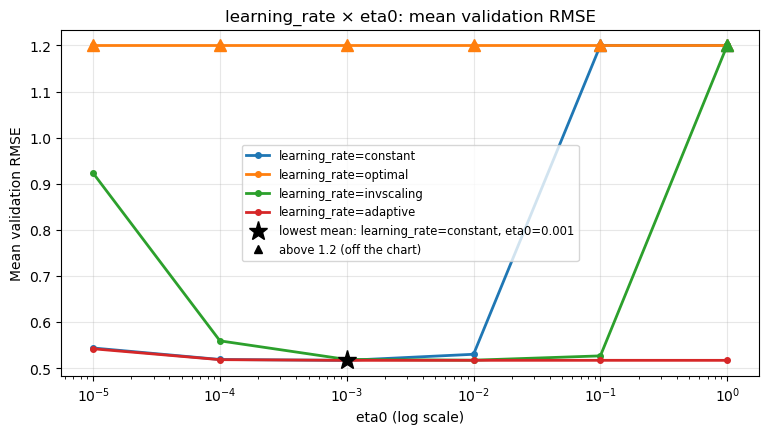

In [25]:
names = cross('learning_rate', LEARNING_RATE_SCHEDULES, 'eta0', ETA0S, SGD_SETTINGS, log_x=True)
learning_rate, eta0 = carried(names, (SGD_SETTINGS['learning_rate'], SGD_SETTINGS['eta0']))
SGD_SETTINGS = {**SGD_SETTINGS, 'learning_rate': learning_rate, 'eta0': eta0}

### Notes / Observations

- `adaptive` is the only schedule that wins: from `eta0` 0.001 to 1 it reaches 0.5175 (-0.0003, SE 0.0003) on 15 to 17 of 20 folds, a candidate at 0.001, 0.01 and 1. They tie to 4 decimals; the carry rule's lowest mean is 0.001, which also stops soonest (33 epochs against 42 and 85), so it is carried.
- Without `adaptive`, the step has to be just right: `constant` at 0.001 has the lowest mean of all 24 pairs (0.5174) but only ties (-0.0004, SE 0.0007, better on 11 of 20 folds), and is worse at 0.01 (+0.0128); `invscaling` only ties at 0.001 and is worse at 0.1 (+0.0093).
- Too large a step diverges: `optimal` at every `eta0` (it ignores `eta0`), `constant` at 0.1 and 1, and `invscaling` at 1. `invscaling` at 1 reads within noise only because its SE is as large as its Δrmse; it is better on 0 of 20 folds.
- Too small a step stops too early under every schedule: at 0.00001 all are worse, from +0.0247 (`adaptive`) to +0.4054 (`invscaling`).

## Tuned SGD vs Closed Form

In [26]:
sgd('SGD, tuned', SGD_SETTINGS)
display(pd.Series(SGD_SETTINGS, name='carried').to_frame())

table(['SGD, tuned'], baseline='Closed form, features')

,carried
penalty,None
learning_rate,adaptive
eta0,0.0010
power_t,0.2500
average,False
max_iter,10000
tol,0.0010
random_state,42


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Closed form, features",0.5175,0.5186,NaN,NaN,,baseline,<NA>
"SGD, tuned",0.5175,0.5186,-0.0000,0.0001,11 of 20,within noise,33


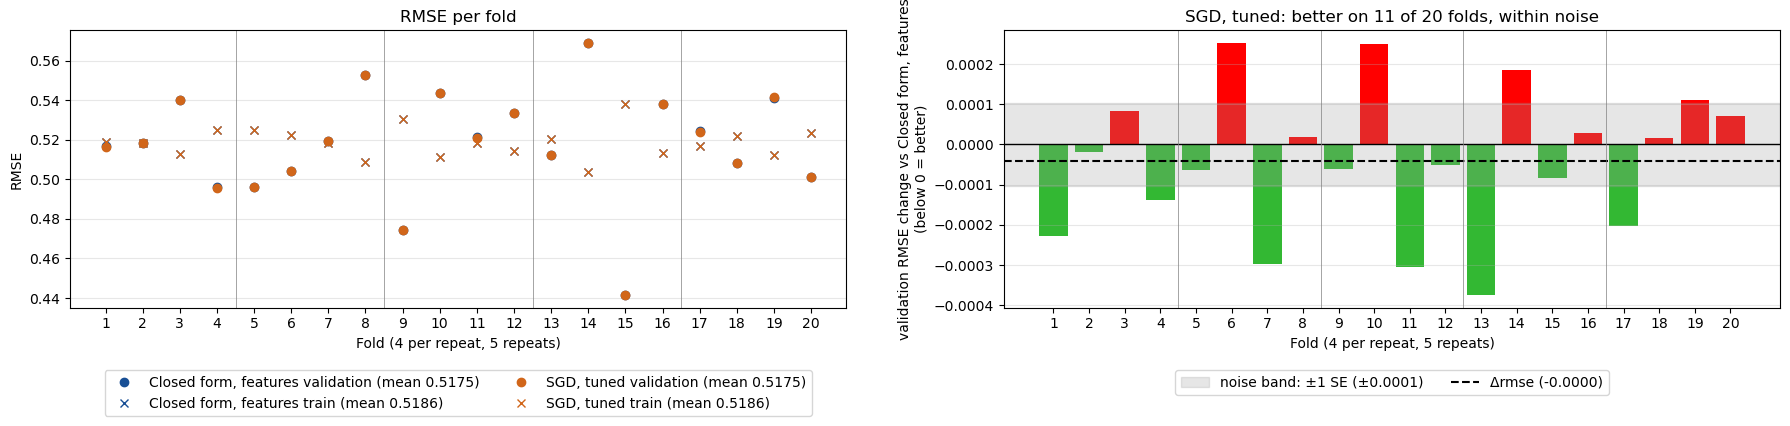

In [27]:
compare('Closed form, features', 'SGD, tuned')

### Notes / Observations

- Tuned SGD reaches the closed form: 0.5175 against 0.5175, within noise (SE 0.0001). With `adaptive` and `eta0` 0.001, SGD finds the same least squares fit as the exact solution.
- Still no overfitting: training RMSE (0.5186) stays above validation RMSE, so a penalty has no gap between the two to close.

# Regularization

The tuned SGD with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, a mix of both), each against the tuned SGD with no penalty. `alpha`, the penalty's strength, is tried at 8 values from 0.000001 to 10. Elastic Net also has `l1_ratio`, its share of L1 in the penalty, so it is searched over every pair of `alpha` and `l1_ratio`, as scikit-learn's `ElasticNetCV` does. SGD's `alpha` is not the same scale as `Ridge`'s: for L2, `Ridge(alpha=n * a)` matches `SGDRegressor(alpha=a)` on n rows.

## Ridge and Lasso

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.5175,0.5186,NaN,NaN,,baseline,33
"Ridge, alpha=1e-06",0.5175,0.5186,-0.0000,0.0000,14 of 20,candidate,33
"Ridge, alpha=1e-05",0.5175,0.5186,-0.0000,0.0000,14 of 20,candidate,33
"Ridge, alpha=0.0001",0.5175,0.5186,-0.0000,0.0000,14 of 20,candidate,33
"Ridge, alpha=0.001",0.5175,0.5186,-0.0000,0.0000,14 of 20,candidate,33
"Ridge, alpha=0.01",0.5174,0.5187,-0.0001,0.0001,14 of 20,within noise,33
"Ridge, alpha=0.1",0.5177,0.5200,0.0002,0.0012,7 of 20,within noise,33
"Ridge, alpha=1",0.5714,0.5749,0.0539,0.0087,0 of 20,worse,35
"Ridge, alpha=10",0.9164,0.9055,0.3990,0.0232,0 of 20,worse,40


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.5175,0.5186,NaN,NaN,,baseline,33
"Lasso, alpha=1e-06",0.5175,0.5186,-0.0000,0.0000,12 of 20,within noise,33
"Lasso, alpha=1e-05",0.5175,0.5186,-0.0000,0.0000,12 of 20,within noise,33
"Lasso, alpha=0.0001",0.5175,0.5186,-0.0000,0.0000,12 of 20,within noise,33
"Lasso, alpha=0.001",0.5175,0.5187,-0.0000,0.0001,11 of 20,within noise,33
"Lasso, alpha=0.01",0.5180,0.5192,0.0005,0.0007,6 of 20,within noise,33
"Lasso, alpha=0.1",0.5450,0.5466,0.0275,0.0061,0 of 20,worse,36
"Lasso, alpha=1",1.1280,1.1085,0.6106,0.0272,0 of 20,worse,31
"Lasso, alpha=10",1.1280,1.1085,0.6106,0.0272,0 of 20,worse,31


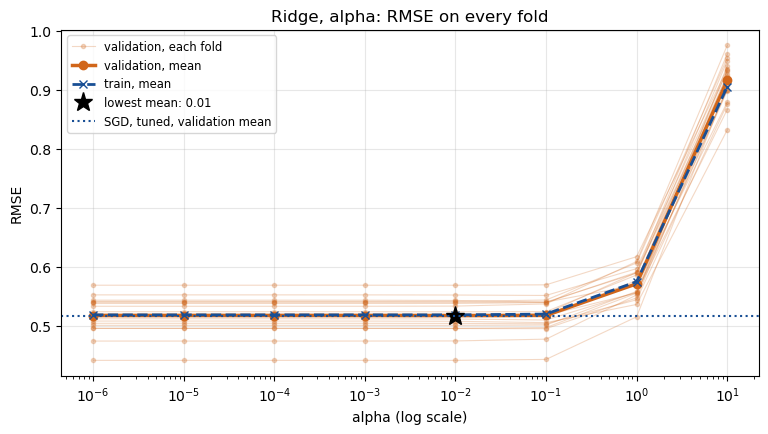

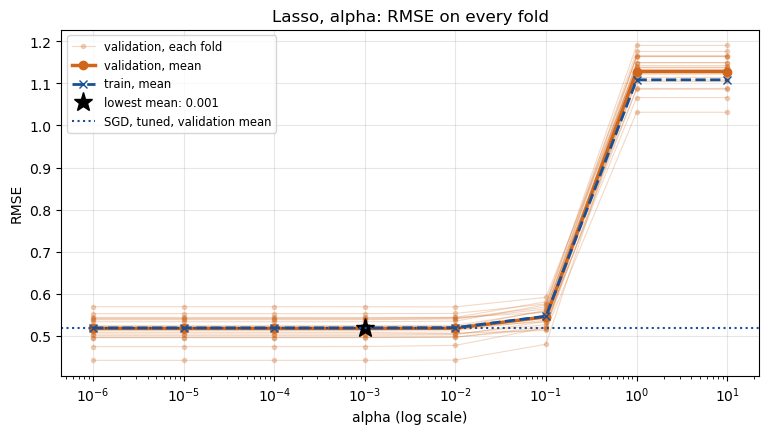

In [28]:
REGULARIZED = []  # every regularized run, the pool the selected model is picked from
for penalty, label in (('l2', 'Ridge'), ('l1', 'Lasso')):
	REGULARIZED += sweep('alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': penalty}, baseline='SGD, tuned', prefix=f'{label}, ', log_x=True).values()

### Notes / Observations

- Small penalties change nothing: up to alpha 0.01, every Ridge and Lasso run is within 0.0005 of no penalty.
- L1 bites first: at alpha 0.1, Lasso is worse by 0.0275 while Ridge is still within noise. Ridge is worse only from alpha 1 (+0.0539).
- Too strong a penalty underfits: training and validation RMSE rise together (Ridge at alpha 10: 0.9055 and 0.9164), the sign of a model too simple, not of one fit to noise.
- Lasso from alpha 1 reaches Dummy's RMSE (1.1280 against 1.1281): the penalty pushes every coefficient to 0, leaving only the mean.
- Ridge's candidate verdicts are not real gains: up to alpha 0.001 they rest on changes that round to 0.0000. The change is almost the same on every fold, so its SE rounds to 0.0000 and any steady change clears it.

## Elastic Net: l1_ratio × alpha

Every pair of the 6 `l1_ratio` values and the 8 `alpha` values. `l1_ratio` 0 would be Ridge and 1 would be Lasso.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.5175,0.5186,NaN,NaN,,baseline,33
"Elastic Net, l1_ratio=0.1, alpha=1e-06",0.5175,0.5186,-0.0000,0.0000,14 of 20,within noise,33
"Elastic Net, l1_ratio=0.1, alpha=1e-05",0.5175,0.5186,-0.0000,0.0000,14 of 20,within noise,33
"Elastic Net, l1_ratio=0.1, alpha=0.0001",0.5175,0.5186,-0.0000,0.0000,14 of 20,within noise,33
"Elastic Net, l1_ratio=0.1, alpha=0.001",0.5175,0.5187,-0.0000,0.0000,13 of 20,within noise,33
"Elastic Net, l1_ratio=0.1, alpha=0.01",0.5174,0.5187,-0.0001,0.0002,12 of 20,within noise,33
"Elastic Net, l1_ratio=0.1, alpha=0.1",0.5190,0.5212,0.0015,0.0016,4 of 20,within noise,35
"Elastic Net, l1_ratio=0.1, alpha=1",0.6201,0.6214,0.1026,0.0129,0 of 20,worse,38
"Elastic Net, l1_ratio=0.1, alpha=10",1.1280,1.1085,0.6106,0.0272,0 of 20,worse,31
"Elastic Net, l1_ratio=0.15, alpha=1e-06",0.5175,0.5186,-0.0000,0.0000,14 of 20,within noise,33


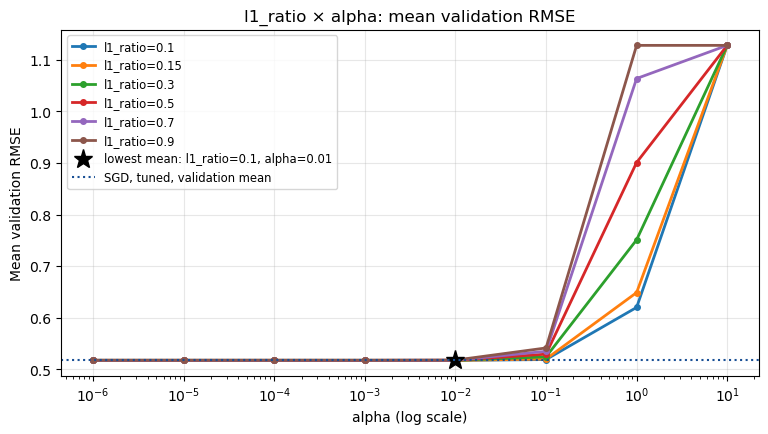

In [29]:
REGULARIZED += cross('l1_ratio', L1_RATIOS, 'alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': 'elasticnet'}, baseline='SGD, tuned', prefix='Elastic Net, ', log_x=True).values()

### Notes / Observations

- Up to alpha 0.01 the mix does not matter: every pair is within noise of no penalty. The lowest mean, `l1_ratio` 0.1 at alpha 0.01 (0.5174), ties it (-0.0001, SE 0.0002).
- Once the penalty acts, more L1 costs more: at alpha 0.1 the cost grows from +0.0015 (`l1_ratio` 0.1, within noise) to +0.0240 (0.9). It follows the Ridge and Lasso sweeps, where Lasso is worse at that alpha and Ridge is not.
- Strong penalties reach the mean sooner with more L1: at alpha 1, `l1_ratio` 0.9 is already at Dummy's RMSE (1.1280) while 0.1 is at 0.6201. At alpha 10 every ratio is.

## Selected Model

The regularized setting with the lowest mean validation RMSE, against the tuned SGD with no penalty.

In [30]:
SELECTED = min(REGULARIZED, key=lambda name: RUNS[name]['validation rmse'].mean())
display(pd.Series(SETTINGS[SELECTED], name=SELECTED).to_frame())

table([SELECTED], baseline='SGD, tuned')

,"Ridge, alpha=0.01"
penalty,l2
learning_rate,adaptive
eta0,0.0010
power_t,0.2500
average,False
max_iter,10000
tol,0.0010
random_state,42
alpha,0.0100


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.5175,0.5186,NaN,NaN,,baseline,33
"Ridge, alpha=0.01",0.5174,0.5187,-0.0001,0.0001,14 of 20,within noise,33


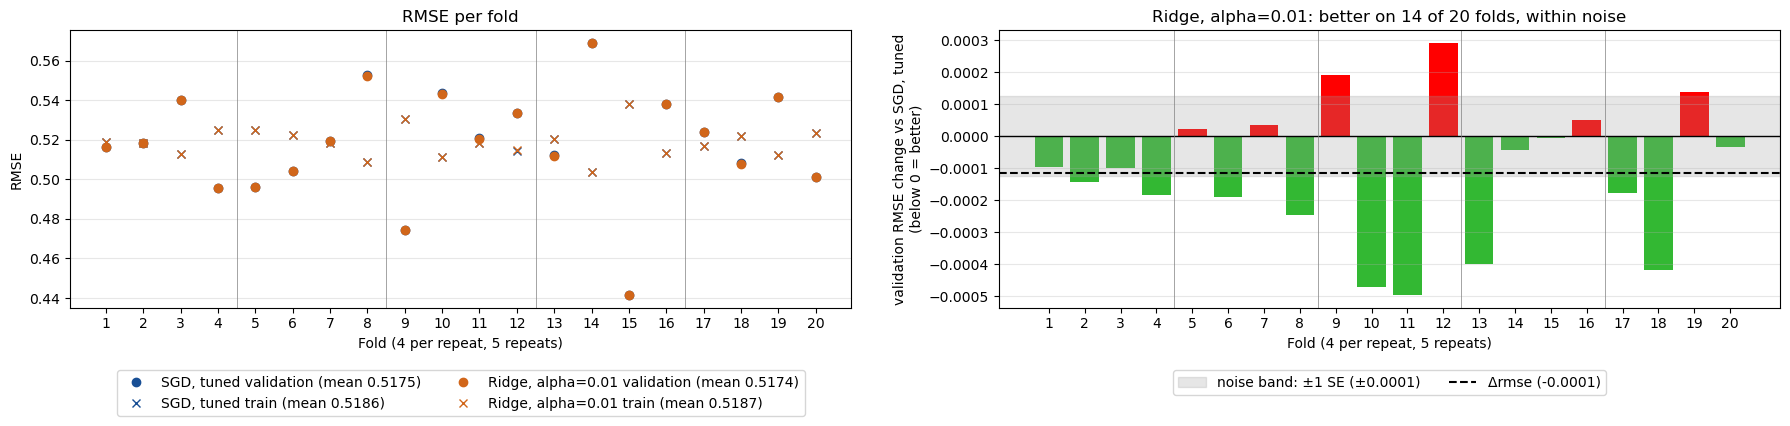

In [31]:
compare('SGD, tuned', SELECTED)

### Notes / Observations

- Selected as required, not because it helps: Ridge at alpha 0.01 has the lowest mean (0.5174, level to 4 decimals with Elastic Net at alpha 0.01 and `l1_ratio` 0.1 or 0.15), 0.0001 below no penalty and within noise (SE 0.0001).
- Nothing to remove: training RMSE (0.5187) sits above validation RMSE (0.5174), so there is no overfitting for a penalty to cure.

## Train on the Entire Training Set

The selected model refit on all 1,559 training rows and saved. The saved pipeline takes the 8 raw attributes and builds its own columns.

In [32]:
final = build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES).fit(X, y)
Q1_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q1_CONSTS.MODEL_OUTPUT_DIR / 'linear_regression.joblib')

pd.Series({
	'training rows': len(X),
	'epochs run': PIPELINES.final_model(final).n_iter_,
	'train rmse': mean_squared_error(y, final.predict(X), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Ridge, alpha=0.01"
training rows,1559
epochs run,32
train rmse,0.5181


## Training and Validation Loss by Epoch

The hint's `warm_start` loop restarts the learning rate schedule on every `fit` call, so epoch k here is a fresh fit with `max_iter=k` and the same seed, exactly the selected model's first k epochs. Once a fold's fit stops on its own (`tol`), its line stays flat. Shown on the 4 folds of the first cut.

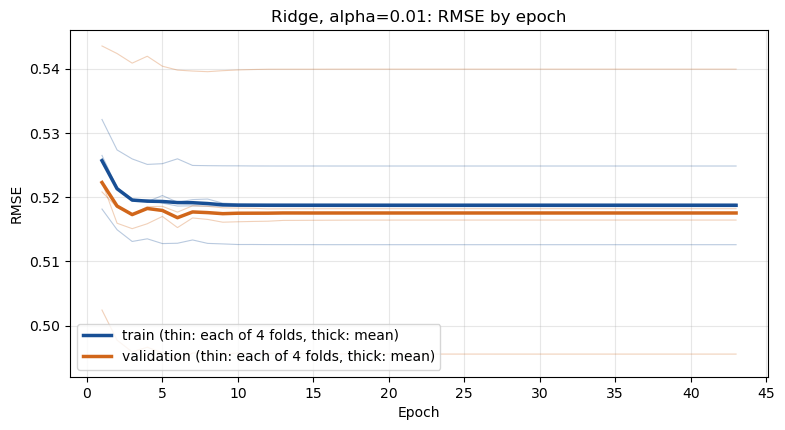

In [33]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max()) + 10  # past the last fold's stop, where every line is flat
curve = PIPELINES.epoch_rmse(pipeline=build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES), X=X, y=y, folds=FOLDS[:CV_SPLITS], epochs=EPOCHS)
PLOTTING.loss_curve(curve=curve, title=f'{SELECTED}: RMSE by epoch');

### Notes / Observations

- The full fit matches cross validation: on all 1,559 rows the selected model stops after 32 epochs, at a training RMSE of 0.5181 against 0.5187 averaged over the folds.
- SGD learns almost everything in its first epoch: both lines start within 0.01 of where they finish, and are flat from about epoch 11.
- No overfitting with more epochs: validation RMSE stays below training RMSE at every epoch, and neither turns back up.